    # QuenchGuard — end-to-end project walkthrough

    **MRI magnet quench early warning: from raw sensor telemetry to a governed
    LLM agent.**

    This notebook is the guided tour of the **whole system**, not just the model.
    Every section reads the artifacts this repository already produced
    (`data/`, `reports/`, `models/`) — nothing is trained and no API key is
    needed, so it runs in under a minute.

    | Section | What it shows |
    |---|---|
    | 1 | The problem, the acceptance criteria, the architecture |
    | 2 | Medallion data layers + lineage hashes (Great Expectations gates) |
    | 3 | 36 causal features and the no-leakage rules |
    | 4 | Champion LSTM vs baselines on the held-out period |
    | 5 | The frozen operating point (false-page budget) |
    | 6 | XAI: global beeswarm + local SHAP + top-3 factors per alert |
    | 7 | Drift monitoring and the retraining trigger |
    | 8 | Fairness audit (event recall policy + Fairlearn DPD/EOD) |
    | 9 | External validation on NASA C-MAPSS FD001 |
    | 10 | The LangGraph agent: tools, RAG, and the human approval gate |
    | 11 | LLMOps: token cost ledger + RAGAS |
    | 12 | Serving: `/predict`, SHAP, and the Art. 12 audit log |
    | 13 | MCP: the standard tool-connection layer |
    | 14 | Deployment: one container, customer UI + API |
    | 15 | Honest limitations and next steps |
    

    ## 1 — Problem, acceptance criteria, architecture

    An MRI magnet quench is a sudden loss of superconductivity: **$120k repair,
    ~5 days of scanner downtime, cancelled patient scans**. The system must warn
    **≥ 72 h ahead** while paging **≤ 1 false alarm per magnet-month**.

    ```
    sensors ─► medallion (bronze → silver → gold) ─► 36 causal features
            ─► 48-step window ─► LSTM ─► P(quench ≤ 96 h) ─► frozen threshold 0.90
            ─► SHAP top-3 ─► API/UI ─► LangGraph agent ─► HITL ticket ─► email
    ```
    

In [1]:
    import json
    import sys
    from pathlib import Path

    REPO_ROOT = Path.cwd()
    sys.path.insert(0, str(REPO_ROOT / "src"))

    %matplotlib inline
    import matplotlib.pyplot as plt
    import pandas as pd

    from quenchguard.config import default_config

    pd.set_option("display.width", 160)
    pd.set_option("display.max_columns", 40)

    cfg = default_config()
    reports = REPO_ROOT / "reports"

    def load_json(name):
        return json.loads((reports / name).read_text(encoding="utf-8"))

    print(f"repo        : {REPO_ROOT}")
    print(f"look-back   : {cfg.window.seq_len} x {cfg.window.step_minutes} min "
          f"= {cfg.window.seq_len * cfg.window.step_minutes // 60} h")
    print(f"label horizon: {cfg.window.horizon_hours} h | acceptance lead "
          f">= {cfg.window.min_lead_hours} h")
    print(f"false-page budget: {cfg.threshold.false_alert_budget_per_magnet_month:g}"
          f" / magnet-month")
    

repo        : C:\Users\avina\OneDrive\Documents\Default Project\mri-quench-predictive-maintenance
look-back   : 48 x 15 min = 12 h
label horizon: 96 h | acceptance lead >= 72 h
false-page budget: 1 / magnet-month


    ## 2 — Medallion data layers and lineage

    * **Bronze** (`data/raw`) — append-only simulator output, never mutated
    * **Silver** (`data/silver`) — cleaned, deduplicated, range-checked; every
      table must pass its Great Expectations suite before it is written
    * **Gold** (`data/gold`) — model-ready feature frame

    Each layer writes a lineage manifest (sha256, rows, schema, config snapshot)
    to `data/lineage/` — the audit trail for EU AI Act Art. 10/11.
    

In [2]:
    lineage_files = sorted((REPO_ROOT / "data" / "lineage").glob("*.json"))
    rows = []
    for path in lineage_files:
        manifest = json.loads(path.read_text(encoding="utf-8"))
        for entry in manifest.get("files", []):
            rows.append({
                "layer": manifest.get("layer", path.stem),
                "table": Path(entry["path"]).name,
                "rows": entry.get("rows"),
                "sha256": str(entry.get("sha256", ""))[:12],
            })
    pd.DataFrame(rows).groupby(["layer", "table", "rows", "sha256"]).size() \
        .rename("n_files").reset_index().tail(10)
    

,layer,table,rows,sha256,n_files
1,bronze,events.csv,311.0,0c45331c7141,1
2,bronze,pressure_1min.parquet,777600.0,fc8d714d166d,1
3,bronze,rf_window.parquet,51834.0,0c03e0d39174,1
4,bronze,vibration_window.parquet,51834.0,2f80bda57555,1
5,gold,features.parquet,51834.0,c628552a2d26,1
6,silver,cold_head.parquet,777600.0,b9cc8b21f53c,1
7,silver,events.csv,311.0,aa5529824aad,1
8,silver,pressure.parquet,777600.0,fc8d714d166d,1
9,silver,rf.parquet,51834.0,0c03e0d39174,1
10,silver,vibration.parquet,51834.0,2f80bda57555,1


In [3]:
    gold = pd.read_parquet(REPO_ROOT / "data" / "gold" / "features.parquet")
    print(f"gold: {len(gold):,} windows x {gold.shape[1]} columns, "
          f"{gold.magnet_id.nunique()} magnets")
    print(f"timeline: {gold.window_end.min()} -> {gold.window_end.max()}")

    counts = load_json("metrics.json")["results"]["lstm"]["classification"]["confusion_matrix"]
    positives = counts["tp"] + counts["fn"]
    print(f"test positive windows: {positives / sum(counts.values()):.2%} "
          f"(and only {counts['tp'] + counts['fn']:,} of {sum(counts.values()):,} rows "
          "are positive — accuracy would be meaningless)")
    gold[["magnet_id", "window_end", "p_mean", "t_mean", "v_rms"]].head(3)
    

gold: 51,834 windows x 38 columns, 6 magnets
timeline: 2025-01-01 00:30:00 -> 2025-04-01 00:00:00
test positive windows: 19.95% (and only 1,536 of 7,699 rows are positive — accuracy would be meaningless)


,magnet_id,window_end,p_mean,t_mean,v_rms
0,MRI-01,2025-01-01 00:30:00,2.390707,4.544736,0.372559
1,MRI-01,2025-01-01 00:45:00,2.388823,4.553317,0.392323
2,MRI-01,2025-01-01 01:00:00,2.384615,4.541705,0.347275


    ## 3 — 36 causal features

    All rolling/lag statistics look strictly backwards. The 7-day trend is fitted
    on **complete calendar days** and joined with a one-day lag; 1-minute signals
    are bucketed as `(t − 15 min, t]`; NaNs are forward-filled within a magnet and
    never back-filled. `tests/test_features.py` asserts the causality property by
    truncating the future.
    

In [4]:
    from quenchguard.features import FEATURE_COLUMNS, FEATURE_GROUPS, feature_documentation

    doc = feature_documentation()
    print(f"{len(FEATURE_COLUMNS)} features in {len(FEATURE_GROUPS)} sensor groups")
    display(doc.groupby("sensor_group").size().rename("n_features").to_frame())
    doc[["feature", "sensor_group", "description"]].head(8)
    

36 features in 4 sensor groups


,n_features
sensor_group,
cold_head_temp,10
helium_pressure,10
rf_power,8
vibration,8


,feature,sensor_group,description
0,p_mean,helium_pressure,Mean helium pressure over the 15-min window (M...
1,p_last,helium_pressure,Pressure at window close — the freshest reading.
2,p_std,helium_pressure,Within-window pressure volatility.
3,p_roll5_mean,helium_pressure,Mean of the causal 5-min rolling average.
4,p_roll30_mean,helium_pressure,Mean of the causal 30-min rolling average.
5,p_delta,helium_pressure,Mean 1-minute pressure change (leak rate proxy).
6,p_delta_max,helium_pressure,Largest 1-minute drop inside the window.
7,p_below_crit_count,helium_pressure,Minutes below the 2.0 MPa failure signal.


    ## 4 — Champion LSTM vs baselines (held-out test period)

    Baselines see only the **last window** (a snapshot); the LSTM also sees the
    **12 h history**. Any win is therefore attributable to temporal context.
    

In [5]:
    metrics = load_json("metrics.json")
    table = pd.DataFrame({
        name: {
            "threshold": r["threshold"],
            "PR-AUC": r["classification"]["pr_auc"],
            "recall": r["classification"]["recall"],
            "event recall >=72h": r["events"]["event_recall_in_time"],
            "lead median (h)": r["events"]["lead_hours_median"],
            "false / magnet-month": r["alerts"]["false_per_magnet_month"],
            "net saving ($)": r["cost"]["net_savings_usd"],
        }
        for name, r in metrics["results"].items()
    }).T
    table
    

,threshold,PR-AUC,recall,event recall >=72h,lead median (h),false / magnet-month,net saving ($)
lstm,0.900000,0.997804,0.999349,1.0,96.000,0.64,452000.0
logreg,0.999468,0.975446,0.658203,0.5,76.250,0.00,228000.0
hist_gbdt,0.993844,0.997322,0.957682,1.0,93.625,0.96,450000.0


    ## 5 — The operating point is a policy decision

    One threshold per model is chosen **on validation** under the false-page
    budget (`1 × 0.6` safety factor), then **frozen** and the test split is scored
    once. The threshold is also overridable at runtime with
    `PREDICTION_THRESHOLD` — no rebuild needed.
    

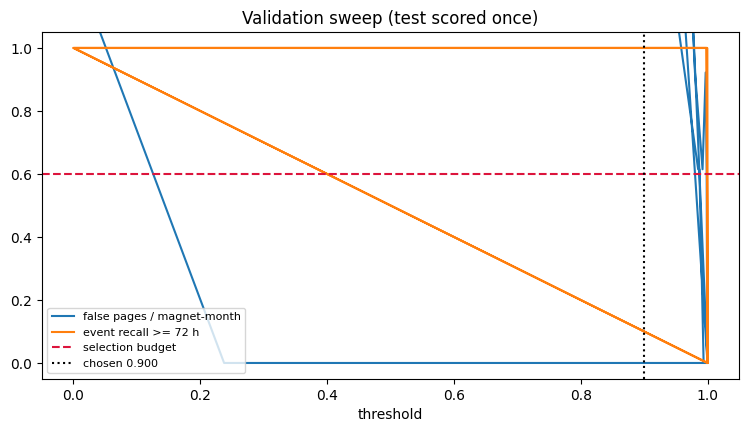

In [6]:
    sweep = pd.read_csv(reports / "threshold_sweep.csv")
    lstm_threshold = metrics["results"]["lstm"]["threshold"]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(sweep.threshold, sweep.false_per_magnet_month, label="false pages / magnet-month")
    ax.plot(sweep.threshold, sweep.event_recall_in_time, label="event recall >= 72 h")
    ax.axhline(cfg.threshold.false_alert_budget_per_magnet_month
               * cfg.threshold.selection_safety_factor,
               color="crimson", ls="--", label="selection budget")
    ax.axvline(lstm_threshold, color="black", ls=":", label=f"chosen {lstm_threshold:.3f}")
    ax.set_xlabel("threshold"); ax.set_ylim(-0.05, 1.05)
    ax.legend(fontsize=8); ax.set_title("Validation sweep (test scored once)")
    plt.show()
    

    ## 6 — Explainability

    * **Global** — beeswarm of |SHAP| across the test set (what the model relies on)
    * **Local** — per-prediction SHAP top-3, returned by `/predict` and shown in the UI

    The champion comparison model is a HistGBDT, so `TreeExplainer` gives exact
    game-theoretic contributions. LIME is unnecessary for a tree ensemble;
    Grad-CAM does not apply (no image input).
    

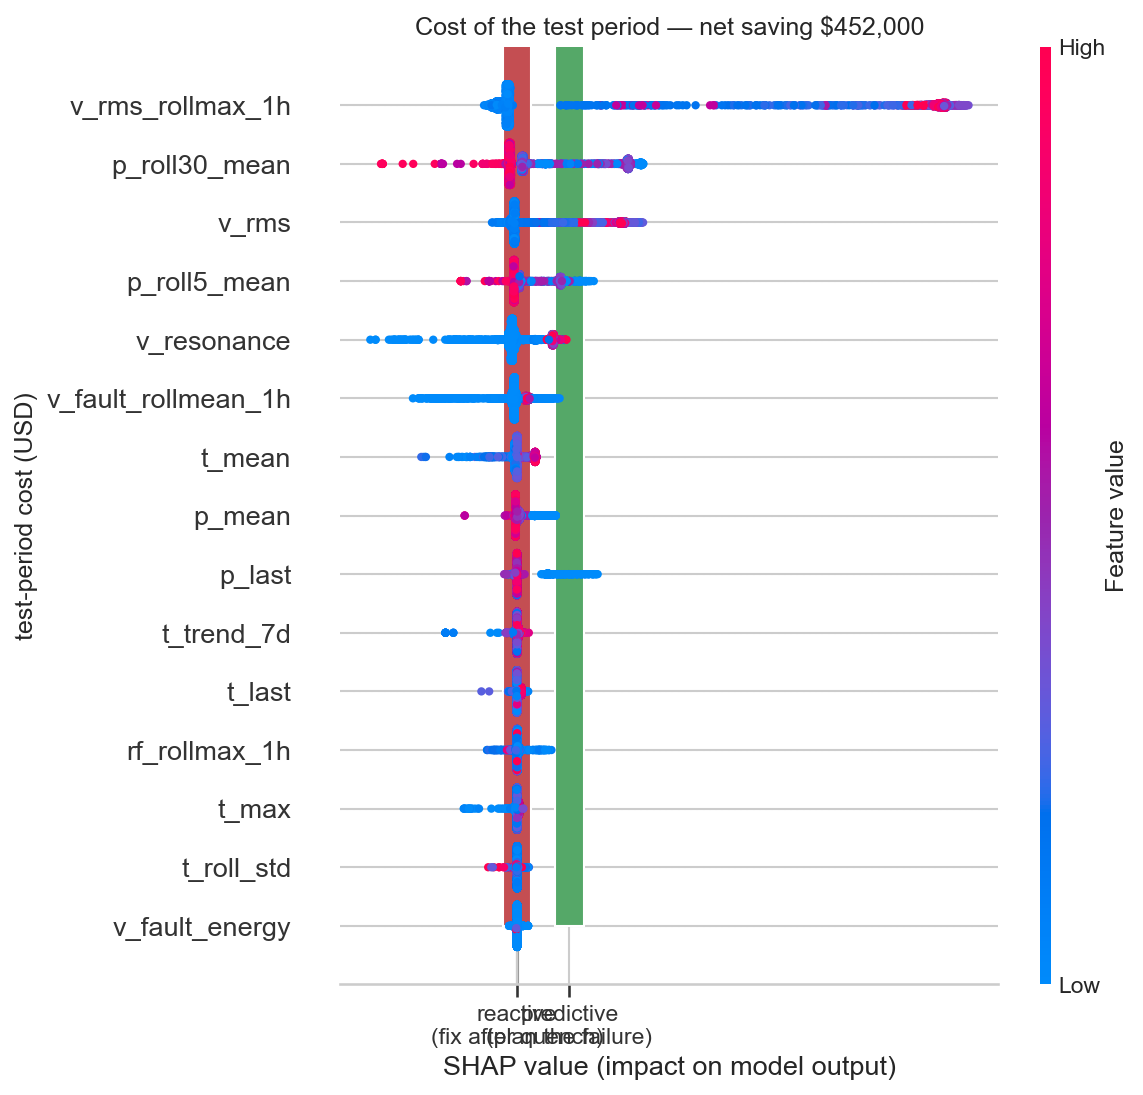

In [7]:
    from IPython.display import Image, display as show

    show(Image(filename=str(reports / "figures" / "shap_beeswarm.png"), width=720))
    

In [8]:
    from quenchguard.serving import Artifacts

    art = Artifacts.load()          # committed serving triple
    demo = pd.read_parquet(REPO_ROOT / "data" / "gold" / "features.parquet") \
        if (REPO_ROOT / "data" / "gold" / "features.parquet").exists() \
        else pd.read_parquet(REPO_ROOT / "data" / "demo" / "features.parquet")
    latest = demo.sort_values("window_end").groupby("magnet_id").tail(1)
    magnet = "MRI-05" if "MRI-05" in set(latest.magnet_id) else str(latest.magnet_id.iloc[0])
    part = demo[demo.magnet_id == magnet].sort_values("window_end")
    window = part.iloc[-art.seq_len:][art.feature_names].values
    result = art.predict(window)

    print(f"magnet      : {magnet}")
    print(f"probability : {result['quench_probability']:.6f}  "
          f"(threshold {result['threshold']:.2f})  alert={result['alert']}")
    print(f"baseline    : {result['baseline_probability']:.6f}")
    pd.DataFrame(result["explanation"])
    

C:\Users\avina\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


magnet      : MRI-05
probability : 0.000692  (threshold 0.90)  alert=False
baseline    : 0.000541


,feature,shap_value,direction
0,v_rms_rollmax_1h,-0.174099,decreases risk
1,p_roll30_mean,-0.138226,decreases risk
2,v_resonance,-0.092341,decreases risk


    ## 7 — Drift monitoring and the retraining trigger

    Evidently `DataDriftPreset(num_method="psi")`: any key feature with PSI > 0.2,
    or more than 25 % of features drifted, sets `retrain_recommended`.
    `scripts/monitor.py --check` exits non-zero so CI turns red — a retraining
    **gate**, deliberately not an automatic loop.
    

In [9]:
    drift = load_json("drift.json")
    print(f"retrain recommended : {drift['retrain_recommended']}")
    print(f"reason              : {drift['reason']}")
    print(f"drifted features    : {drift['drifted_share']:.0%} of the feature set")
    pd.Series(drift["psi"]).sort_values(ascending=False).head(8).to_frame("PSI")
    

retrain recommended : True
reason              : key feature(s) drifted: p_roll30_mean, p_roll5_mean, p_mean, v_rms_rollmax_1h, v_rms
drifted features    : 25% of the feature set


,PSI
p_roll30_mean,1.560835
p_roll5_mean,1.541958
p_mean,1.533618
p_last,1.366612
p_trend_7d,0.611635
p_below_crit_count,0.392159
v_rms_rollmax_1h,0.253033
t_trend_7d,0.231802


    ## 8 — Fairness: safety equity first, parity second

    The deployed policy is **event-level recall** (every quench on every
    event-bearing magnet must be caught ≥ 72 h ahead) plus alert-burden parity
    **among alerting magnets**. Clean magnets correctly never alert, so a naive
    demographic-parity metric penalises correctness — that is why Fairlearn's
    DPD/EOD are reported for the audit trail but are not the gate.
    

In [10]:
    fair = load_json("fairness.json")
    print(f"verdict                     : {fair['verdict'].upper()}")
    print(f"selection-rate difference   : {fair['selection_rate_difference']:.3f} "
          f"(max {fair['max_selection_rate_difference']})")
    print(f"FPR difference              : {fair['fpr_difference']:.3f} "
          f"(max {fair['max_fpr_difference']})")
    print(f"Fairlearn DPD / EOD         : {fair['demographic_parity_difference']} / "
          f"{fair['equalized_odds_difference']}  <- all magnets, incl. event-free ones")
    pd.DataFrame({
        "event recall >=72h": fair["event_recall_by_magnet"],
        "selection rate": {m: r["selection_rate"]
                           for m, r in fair["metrics"]["by_group"].items()},
    })
    

verdict                     : PASS
selection-rate difference   : 0.126 (max 0.2)
FPR difference              : 0.066 (max 0.1)
Fairlearn DPD / EOD         : 0.4387 / 1.0  <- all magnets, incl. event-free ones


,event recall >=72h,selection rate
MRI-01,1.0,0.438669
MRI-02,1.0,0.353047
MRI-03,NaN,0.000000
MRI-04,NaN,0.000000
MRI-05,1.0,0.313030
MRI-06,1.0,0.400208


    ## 9 — External validation (NASA C-MAPSS FD001)

    The MRI data is synthetic, so the *methodology* is validated on real turbofan
    run-to-failure data with the same discipline: 30-cycle horizon, 15-cycle
    deadline, engine-grouped split, honest censoring denominators. This is
    evidence for the method, **not** proof that the MRI model transfers.
    

In [11]:
    ext = load_json("external_validation.json")
    champ = ext["champion"]
    test = ext["results"][champ]["test"]
    print(f"dataset   : {ext['dataset']}   champion: {champ}")
    print(f"PR-AUC    : {test['window']['pr_auc']:.3f}")
    print(f"event recall: {test['events']['event_recall']:.0%} "
          f"({test['events']['detected']}/{test['n_observable_events']} observable)")
    print(f"false alerts per engine-month: {test['alerts']['false_per_unit']:.2f}")
    

dataset   : {'name': 'NASA C-MAPSS FD001', 'citation': 'Saxena & Goebel (2008), NASA Prognostics Data Repository', 'train_rows': 20631, 'train_units': 100, 'test_rows': 13096, 'test_units': 100, 'informative_sensors': ['s2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21'], 'dropped_constant_sensors': ['s1', 's5', 's10', 's16', 's18', 's19'], 'provenance': {'train_FD001.txt': {'sha256': '963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8834ba4b5d91d2de0f8', 'bytes': 3515356}, 'test_FD001.txt': {'sha256': '3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf95eb55d1ddd6f52851', 'bytes': 2228855}, 'RUL_FD001.txt': {'sha256': 'a19c8ec94931949d0485bdc35118206e9c81c4547b422efb9cf86f4ceddbceca', 'bytes': 429}}}   champion: hist_gbdt
PR-AUC    : 0.892
event recall: 84% (21/25 observable)
false alerts per engine-month: 0.18


    ## 10 — The LangGraph agent: tools, RAG, and the human gate

    The agent can **score, read telemetry and search docs** — but `create_ticket`
    sits behind a LangGraph `interrupt()`. Below, a deterministic scripted LLM
    drives the real graph: the first turn calls `doc_search` (RAG), and the
    ticket turn stops at the gate with a payload the UI renders as
    **Approve / Reject**.
    

In [12]:
    from quenchguard.agent import ScriptedLLM, build_graph, doc_search
    from langchain_core.messages import AIMessage

    hits = doc_search("false page budget threshold policy", k=3)
    pd.DataFrame([{"source": h["source"], "heading": h["heading"],
                   "score": round(h["score"], 3)} for h in hits])
    

,source,heading,score
0,model_card.md,Retraining policy,0.218
1,model_card.md,Model details,0.189
2,model_card.md,Monitoring and lifecycle,0.126


In [13]:
    tool_call = AIMessage(content="", tool_calls=[{
        "name": "doc_search", "args": {"query": "quench risk"}, "id": "c1",
        "type": "tool_call"}])
    graph = build_graph(ScriptedLLM([tool_call, AIMessage(content="Grounded answer.")]))

    cfg_thread = {"configurable": {"thread_id": "walkthrough-agent"}}
    out = graph.invoke({"messages": [("user", "what does the model card say?")]}, cfg_thread)
    for msg in out["messages"]:
        print(f"{msg.type:>9}: {str(msg.content)[:110]}")
    

    human: what does the model card say?
       ai: 
     tool: [{"source": "model_card.md", "heading": "Limitations", "text": "* Trained on **synthetic** MRI data; physics p
       ai: Grounded answer.


In [14]:
    import tempfile
    from quenchguard import agent as A

    tmp = Path(tempfile.mkdtemp(prefix="qg_hitl_"))
    A.REPORTS_DIR = tmp

    ticket_call = AIMessage(content="", tool_calls=[{
        "name": "create_ticket",
        "args": {"magnet_id": "MRI-05", "priority": "low",
                 "summary": "Gradual helium-pressure drift, still above limits.",
                 "recommended_action": "Schedule a cryo check within 7 days."},
        "id": "c2", "type": "tool_call"}])
    g2 = build_graph(ScriptedLLM([ticket_call, AIMessage(content="Ticket created.")]))
    cfg2 = {"configurable": {"thread_id": "walkthrough-hitl"}}
    first = g2.invoke({"messages": [("user", "open a ticket for MRI-05")]}, cfg2)

    pending = first["__interrupt__"][0].value
    print("PAUSED at the human gate:")
    print(json.dumps(pending["args"], indent=2)[:700])
    print("\ntickets written before approval:", len(list(tmp.glob("tickets/*.md"))))
    

PAUSED at the human gate:
{
  "magnet_id": "MRI-05",
  "priority": "low",
  "summary": "Gradual helium-pressure drift, still above limits.",
  "recommended_action": "Schedule a cryo check within 7 days."
}

tickets written before approval: 0


In [15]:
    from langgraph.types import Command

    final = g2.invoke(Command(resume={"approved": True}), cfg2)
    tickets = list(tmp.glob("tickets/*.md"))
    print("tickets after approval:", len(tickets))
    print(tickets[0].read_text(encoding="utf-8")[:420])
    

tickets after approval: 1
# Service ticket — MRI-05

- created: 2026-11-19T07:58:26.052812+00:00
- priority: **low**
- approved by: human operator (HITL gate)

## Summary
Gradual helium-pressure drift, still above limits.

## Recommended action
Schedule a cryo check within 7 days.



    ## 11 — LLMOps evidence

    * Token/cost ledger prices dated snapshots (`gpt-4o-mini-2024-07-18` → family)
    * Production wrapper: retries with backoff, 60 s timeout, per-call token ceiling
    * RAGAS judges grounding (faithfulness) and relevance on a small Q&A set
    

In [16]:
    costs = load_json("agent_costs.json")
    ragas = load_json("ragas_scores.json")
    pd.DataFrame([
        {"metric": "agent calls", "value": costs["n_calls"]},
        {"metric": "prompt tokens", "value": costs["prompt_tokens"]},
        {"metric": "completion tokens", "value": costs["completion_tokens"]},
        {"metric": "cost (USD)", "value": costs["cost_usd"]},
        {"metric": "RAGAS faithfulness", "value": ragas["faithfulness"]},
        {"metric": "RAGAS answer relevancy", "value": ragas["answer_relevancy"]},
    ])
    

,metric,value
0,agent calls,2.000000
1,prompt tokens,1086.000000
2,completion tokens,68.000000
3,cost (USD),0.000204
4,RAGAS faithfulness,0.750000
5,RAGAS answer relevancy,0.900100


    ## 12 — Serving: predictions with explanations and an audit record

    Every `/predict` call returns the probability, threshold, baseline and SHAP
    top-3, **and** appends one JSONL record (Art. 12): UTC timestamp, magnet,
    input sha256, output, threshold, top factors, model provenance.
    

In [17]:
    import os
    import numpy as np
    from fastapi.testclient import TestClient
    from quenchguard.webui import create_app

    audit_path = tmp / "prediction_log.jsonl"
    os.environ["PREDICTION_LOG_PATH"] = str(audit_path)
    os.environ.pop("PREDICTION_LOG", None)

    client = TestClient(create_app())
    window = np.zeros((art.seq_len, len(art.feature_names))).tolist()
    response = client.post("/predict", json={"magnet_id": "MRI-05", "window": window})
    body = response.json()
    print(response.status_code, {k: body[k] for k in
          ("quench_probability", "alert", "threshold", "baseline_probability")})
    record = json.loads(audit_path.read_text(encoding="utf-8").strip().splitlines()[-1])
    print("audit record keys:", sorted(record))
    

200 {'quench_probability': 0.020321, 'alert': False, 'threshold': 0.9, 'baseline_probability': 0.002967}
audit record keys: ['alert', 'baseline_probability', 'input_sha256', 'latency_ms', 'magnet_id', 'model_name', 'model_source', 'model_version', 'quench_probability', 'threshold', 'top_factors', 'ts']


    ## 13 — MCP: one standard connection layer

    Instead of a bespoke integration per client, the read-only tools are exposed
    over MCP (stdio / SSE / streamable HTTP). `create_ticket` is deliberately
    **absent** — it cannot be called by any external client.
    

In [18]:
    import asyncio
    import concurrent.futures
    from quenchguard.mcp_server import mcp

    with concurrent.futures.ThreadPoolExecutor() as pool:
        tools = pool.submit(lambda: asyncio.run(mcp.list_tools())).result()
    print("advertised tools:", [t.name for t in tools])
    print("create_ticket exposed:", "create_ticket" in {t.name for t in tools})
    

advertised tools: ['fleet_risk', 'score_magnet', 'sensor_summary', 'doc_search']
create_ticket exposed: False


    ## 14 — Deployment: one image, customer UI + streaming API

    The Dockerfile is multi-stage: Node builds the Next.js static export, Python
    serves it at `/` together with `/api/*` (SSE chat) and `/predict`.

    ```bash
    docker build -t quenchguard .
    docker run -p 8000:8000 -e OPENAI_API_KEY=sk-... quenchguard
    # UI http://localhost:8000 · chat /api/chat · model /predict
    ```

    Nightly-operations knobs: `PREDICTION_THRESHOLD`, `MODEL_SOURCE=registry`
    (falls back to local), `PREDICTION_LOG_PATH`, `LLM_MAX_TOKENS`, SMTP ticket
    alerts. CI runs the test matrix, the pipeline smoke test, the Docker image
    (including a UI check) and the frontend build.
    

    ## 15 — Honest limitations and next steps

    **Limitations**

    * Synthetic MRI data — plausible physics, not clinically validated; the
      methodology is externally validated on C-MAPSS.
    * Probabilities are not calibrated risk estimates; 0.90 is a policy
      threshold, not a clinical number.
    * 4 test quench events is a small sample: read the lead-time distribution.
    * RAG is TF-IDF (offline, deterministic); production would use embeddings +
      a vector store with reranking.
    * Automated retraining is a gate (`monitor.py --check`), not a closed loop.

    **Next steps**

    1. Replay on a rolling origin (walk-forward) rather than one test cut.
    2. Isotonic calibration on validation before the threshold sweep.
    3. Vector-store RAG + context-recall evaluation.
    4. Automated retraining with promotion gates (MLflow stage → shadow → prod).
    5. Durable checkpointer (`langgraph-checkpoint-sqlite`) for multi-instance
       deployments of the HITL flow.

    ---
    ### Reproduce

    ```bash
    python scripts/run_pipeline.py                  # data → model → reports
    python scripts/build_project_notebook.py        # rebuild + execute this notebook
    python scripts/build_notebook.py                # the model-training notebook
    python scripts/serve.py                         # customer UI + API
    python -m pytest                                # 146 tests
    ```
    